# AgriCLIP-Guided Fine-Tuned SAM2 on VegAnn

### Pipeline

VegAnn image  
→ overlapping patches  
→ frozen DINO ResNet-50  
→ VegAnn-trained AgriCLIP aligner  
→ vegetation similarity heatmap  
→ automatic box and point prompts  
→ fine-tuned SAM2  
→ vegetation segmentation

### Experiment objective

This notebook evaluates whether AgriCLIP can automatically generate useful spatial prompts for a fine-tuned SAM2 model without using ExG or ground-truth prompts.

In [1]:
import os
import sys
import random
import json
import time
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn.functional as F

from PIL import Image

import matplotlib.pyplot as plt

from torchvision import transforms
from datasets import load_dataset

from tqdm.auto import tqdm


warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)

PyTorch version: 2.12.0+cu130


In [2]:
SEED = 42


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Reproducibility settings
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("Seed:", SEED)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

Seed: 42
Device: cuda
GPU: NVIDIA GeForce RTX 4090
GPU memory: 23.52 GB


In [3]:
#Defining project paths 
PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

AGRICLIP_ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

VEGANN_ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)



# ---------------------------------------------------------

FINETUNED_SAM2_CHECKPOINT = Path(
    "/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt"
)


print("Project root:")
print(PROJECT_ROOT)

print("\nAgriCLIP repository:")
print(AGRICLIP_ROOT)

print("\nAgriCLIP alignment directory:")
print(AGRICLIP_ALIGNMENT_DIR)

print("\nVegAnn aligner:")
print(VEGANN_ALIGNER_PATH)

print("\nFine-tuned SAM2 checkpoint:")
print(FINETUNED_SAM2_CHECKPOINT)


Project root:
/home/zahranadeem/thesis

AgriCLIP repository:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP

AgriCLIP alignment directory:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment

VegAnn aligner:
/home/zahranadeem/thesis/vegann_aligner.pth

Fine-tuned SAM2 checkpoint:
/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt


In [4]:
#verifying paths and creating output directories 
assert PROJECT_ROOT.exists(), (
    f"Project root does not exist:\n{PROJECT_ROOT}"
)

assert AGRICLIP_ROOT.exists(), (
    f"AgriCLIP repository does not exist:\n{AGRICLIP_ROOT}"
)

assert AGRICLIP_ALIGNMENT_DIR.exists(), (
    f"AgriCLIP alignment directory does not exist:\n"
    f"{AGRICLIP_ALIGNMENT_DIR}"
)

assert VEGANN_ALIGNER_PATH.exists(), (
    f"VegAnn aligner does not exist:\n"
    f"{VEGANN_ALIGNER_PATH}"
)


OUTPUT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "agriclip_guided_sam2"
)

HEATMAP_DIR = OUTPUT_ROOT / "heatmaps"
CANDIDATE_MASK_DIR = OUTPUT_ROOT / "candidate_masks"
PREDICTION_DIR = OUTPUT_ROOT / "predictions"
FIGURE_DIR = OUTPUT_ROOT / "figures"
METRICS_DIR = OUTPUT_ROOT / "metrics"


for directory in [
    OUTPUT_ROOT,
    HEATMAP_DIR,
    CANDIDATE_MASK_DIR,
    PREDICTION_DIR,
    FIGURE_DIR,
    METRICS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


print("Required AgriCLIP paths found.")
print("Output directory:", OUTPUT_ROOT)

Required AgriCLIP paths found.
Output directory: /home/zahranadeem/thesis/results/agriclip_guided_sam2


In [9]:
#Loading VegAnn
vegann = load_dataset("simonMadec/VegAnn")

print(vegann)
print("Columns:", vegann["train"].column_names)
print("Number of images:", len(vegann["train"]))


DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Number of images: 3775


In [10]:
#Creating the val/train split 

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print("Training images:", len(train_hf))
print("Validation images:", len(val_hf))

Training images: 3020
Validation images: 755


In [12]:
#Set image and mask coloumn names 

column_names = vegann["train"].column_names

image_candidates = [
    "image",
    "images",
    "rgb",
    "img"
]

mask_candidates = [
    "mask",
    "masks",
    "label",
    "labels",
    "segmentation_mask",
    "annotation"
]

IMAGE_KEY = next(
    (key for key in image_candidates if key in column_names),
    None
)

MASK_KEY = next(
    (key for key in mask_candidates if key in column_names),
    None
)

print("Detected image column:", IMAGE_KEY)
print("Detected mask column:", MASK_KEY)

if IMAGE_KEY is None or MASK_KEY is None:
    raise ValueError(
        f"Could not automatically detect the columns. "
        f"Available columns: {column_names}"
    )

Detected image column: image
Detected mask column: mask


In [17]:
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


dino_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


print(dino_transform)

def ensure_rgb_pil(image):
    """
    Convert an input image to an RGB PIL image.
    """

    if isinstance(image, Image.Image):
        return image.convert("RGB")

    image = np.asarray(image)

    if image.dtype != np.uint8:
        image = np.clip(
            image,
            0,
            255
        ).astype(np.uint8)

    return Image.fromarray(
        image
    ).convert("RGB")


def mask_to_binary_numpy(mask):
    """
    Convert a PIL image, tensor, or NumPy mask
    into a binary uint8 array with values {0, 1}.
    """

    if isinstance(mask, Image.Image):
        mask = np.array(mask)

    elif torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    else:
        mask = np.asarray(mask)

    # Remove unnecessary singleton dimensions
    mask = np.squeeze(mask)

    # If the mask is RGB, use the first channel.
    if mask.ndim == 3:
        mask = mask[..., 0]

    binary_mask = (
        mask > 0
    ).astype(np.uint8)

    return binary_mask


def calculate_iou(pred_mask, gt_mask, epsilon=1e-7):
    """
    Binary intersection over union.
    """

    pred_mask = (
        np.asarray(pred_mask) > 0
    )

    gt_mask = (
        np.asarray(gt_mask) > 0
    )

    intersection = np.logical_and(
        pred_mask,
        gt_mask
    ).sum()

    union = np.logical_or(
        pred_mask,
        gt_mask
    ).sum()

    if union == 0:
        return 1.0

    return float(
        intersection / (union + epsilon)
    )


def calculate_dice(pred_mask, gt_mask, epsilon=1e-7):
    """
    Binary Dice coefficient.
    """

    pred_mask = (
        np.asarray(pred_mask) > 0
    )

    gt_mask = (
        np.asarray(gt_mask) > 0
    )

    intersection = np.logical_and(
        pred_mask,
        gt_mask
    ).sum()

    denominator = (
        pred_mask.sum()
        + gt_mask.sum()
    )

    if denominator == 0:
        return 1.0

    return float(
        (2.0 * intersection)
        / (denominator + epsilon)
    )
def get_image(idx, split=val_hf):
    """
    Returns a PIL RGB image.
    """
    return ensure_rgb_pil(
        split[idx][IMAGE_KEY]
    )


def get_mask(idx, split=val_hf):
    """
    Returns a binary numpy mask.
    """
    return mask_to_binary_numpy(
        split[idx][MASK_KEY]
    )

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


Image size: (512, 512)
Image mode: RGB
Mask shape: (512, 512)
Mask values: [0 1]


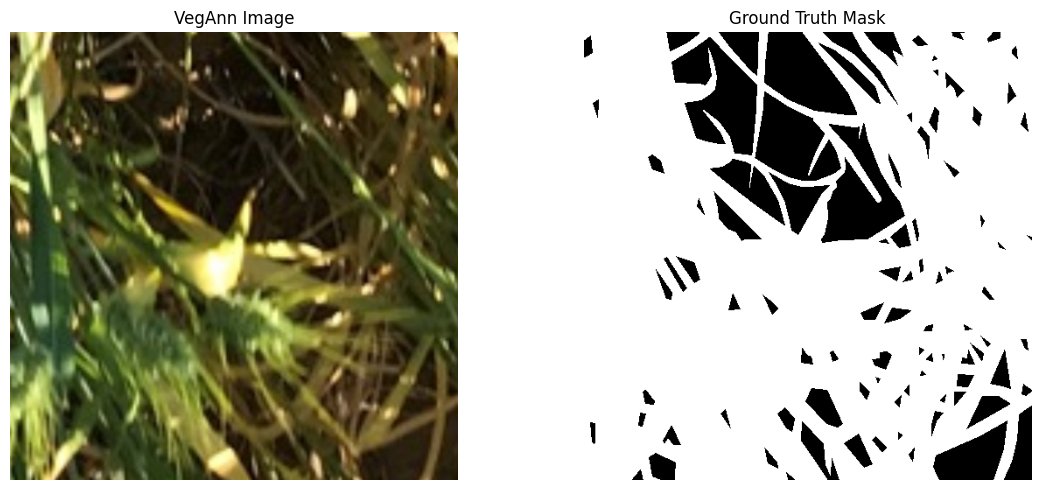

In [16]:
# Visualize one validation sample

sample = val_hf[0]

sample_image = ensure_rgb_pil(
    sample[IMAGE_KEY]
)

sample_gt_mask = mask_to_binary_numpy(
    sample[MASK_KEY]
)

print("Image size:", sample_image.size)
print("Image mode:", sample_image.mode)

print("Mask shape:", sample_gt_mask.shape)
print("Mask values:", np.unique(sample_gt_mask))

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(sample_image)
plt.title("VegAnn Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(sample_gt_mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

# AGRICLIP LOADING 

VegAnn image
    ↓
DINO ResNet-50
    ↓
2048-dimensional feature
    ↓
VegAnn aligner
    ↓
512-dimensional AgriCLIP feature
    ↓
comparison with vegetation and background text

A positive or negative value here is not yet enough to judge localization. The important test comes next, when we divide the image into overlapping patches and produce the spatial AgriCLIP heatmap.

In [18]:
# Add the AgriCLIP alignment folder to Python's import path

AGRICLIP_ALIGNMENT_DIR_STR = str(
    AGRICLIP_ALIGNMENT_DIR
)

if AGRICLIP_ALIGNMENT_DIR_STR not in sys.path:
    sys.path.insert(
        0,
        AGRICLIP_ALIGNMENT_DIR_STR
    )


print("AgriCLIP alignment directory added:")
print(AGRICLIP_ALIGNMENT_DIR_STR)


# Verify that the required Python files exist

required_files = [
    AGRICLIP_ALIGNMENT_DIR / "TextToConcept.py",
    AGRICLIP_ALIGNMENT_DIR / "LinearAligner.py"
]

for file_path in required_files:
    assert file_path.exists(), (
        f"Required file not found:\n{file_path}"
    )

    print("Found:", file_path.name)

AgriCLIP alignment directory added:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment
Found: TextToConcept.py
Found: LinearAligner.py


In [19]:
#Importing AGRICLIP classes 
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner


print("TextToConcept imported successfully")
print("LinearAligner imported successfully")

TextToConcept imported successfully
LinearAligner imported successfully


In [20]:
# Load the same DINO model used for aligner training

dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_model = dino_model.to(device)
dino_model.eval()


# Freeze all DINO parameters

for parameter in dino_model.parameters():
    parameter.requires_grad = False


print("DINO model loaded")
print("Model:", dino_model.__class__.__name__)
print("Device:", device)
print(
    "Trainable parameters:",
    sum(
        parameter.requires_grad
        for parameter in dino_model.parameters()
    )
)

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


DINO model loaded
Model: ResNet
Device: cuda
Trainable parameters: 0


In [21]:
# Create the TextToConcept wrapper and loading VegAnn aloigner

text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50"
)


# Load the aligner that you trained on VegAnn captions

text_to_concept.load_linear_aligner(
    str(VEGANN_ALIGNER_PATH)
)


print("TextToConcept created")
print("VegAnn aligner loaded successfully")

TextToConcept created
VegAnn aligner loaded successfully


In [ ]:
aligner = text_to_concept.linear_aligner


print("\nAligner details")

print(
    "W shape:",
    tuple(aligner.W.shape)
)

print(
    "b shape:",
    tuple(aligner.b.shape)
)

print(
    "W device:",
    aligner.W.device
)

print(
    "b device:",
    aligner.b.device
)

print(
    "W dtype:",
    aligner.W.dtype
    
)


Aligner details
W shape: (512, 2048)
b shape: (512,)
W device: cuda:0
b device: cuda:0
W dtype: torch.float32


In [23]:
#defining AgriCLIP text prompts
POSITIVE_PROMPTS = [
    "vegetation",
    "green vegetation",
    "crop vegetation",
    "plants growing in an agricultural field",
    "green crop plants",
    "leaves and stems of crop plants"
]


NEGATIVE_PROMPTS = [
    "bare soil",
    "agricultural soil without vegetation",
    "empty field without plants",
    "dirt and stones",
    "dry soil",
    "background without vegetation"
]


print("Positive prompts:")

for prompt in POSITIVE_PROMPTS:
    print("  +", prompt)


print("\nNegative prompts:")

for prompt in NEGATIVE_PROMPTS:
    print("  -", prompt)

Positive prompts:
  + vegetation
  + green vegetation
  + crop vegetation
  + plants growing in an agricultural field
  + green crop plants
  + leaves and stems of crop plants

Negative prompts:
  - bare soil
  - agricultural soil without vegetation
  - empty field without plants
  - dirt and stones
  - dry soil
  - background without vegetation


In [24]:
#Encode pos and neg prompts 
with torch.inference_mode():

    positive_text_feature = (
        text_to_concept.encode_text(
            [POSITIVE_PROMPTS]
        )
    )

    negative_text_feature = (
        text_to_concept.encode_text(
            [NEGATIVE_PROMPTS]
        )
    )


positive_text_feature = F.normalize(
    positive_text_feature.float(),
    dim=-1
)

negative_text_feature = F.normalize(
    negative_text_feature.float(),
    dim=-1
)


print(
    "Positive text feature shape:",
    positive_text_feature.shape
)

print(
    "Negative text feature shape:",
    negative_text_feature.shape
)

print(
    "Positive feature norm:",
    positive_text_feature.norm(
        dim=-1
    )
)

print(
    "Negative feature norm:",
    negative_text_feature.norm(
        dim=-1
    )
)

Positive text feature shape: torch.Size([1, 512])
Negative text feature shape: torch.Size([1, 512])
Positive feature norm: tensor([1.], device='cuda:0')
Negative feature norm: tensor([1.], device='cuda:0')


In [25]:
#checking text dimensions match the aligner output 
ALIGNER_OUTPUT_DIM = aligner.W.shape[0]
TEXT_FEATURE_DIM = positive_text_feature.shape[-1]


print("Aligner output dimension:", ALIGNER_OUTPUT_DIM)
print("Text feature dimension:", TEXT_FEATURE_DIM)


assert ALIGNER_OUTPUT_DIM == TEXT_FEATURE_DIM, (
    "The aligner output dimension does not match "
    "the CLIP text embedding dimension."
)


print("Dimensions match successfully.")

Aligner output dimension: 512
Text feature dimension: 512
Dimensions match successfully.


In [30]:
#checking the complete AGRICLIP chain on one full image 
@torch.inference_mode()
def extract_dino_features(pil_images):
    """
    Extract frozen DINO ResNet-50 features.

    Parameters
    ----------
    pil_images:
        One PIL image or a list of PIL images.

    Returns
    -------
    torch.Tensor
        Shape: [batch_size, feature_dimension]
    """

    if isinstance(pil_images, Image.Image):
        pil_images = [pil_images]

    elif not isinstance(pil_images, (list, tuple)):
        pil_images = list(pil_images)

    image_batch = torch.stack([
        dino_transform(
            ensure_rgb_pil(image)
        )
        for image in pil_images
    ]).to(device)

    # DINO ResNet-50 uses the normal forward method
    features = dino_model(
        image_batch
    )

    # Handle one-image output if necessary
    if features.ndim == 1:
        features = features.unsqueeze(0)

    features = features.flatten(
        start_dim=1
    ).float()

    return features


In [31]:
sample_image = get_image(
    0,
    split=val_hf
)

sample_dino_feature = extract_dino_features(
    sample_image
)

print(
    "DINO feature shape:",
    sample_dino_feature.shape
)

print(
    "Aligner expected input dimension:",
    aligner.W.shape[1]
)

assert sample_dino_feature.shape[1] == aligner.W.shape[1], (
    f"DINO output dimension "
    f"{sample_dino_feature.shape[1]} does not match "
    f"aligner input dimension {aligner.W.shape[1]}."
)

print("DINO output matches the VegAnn aligner.")

DINO feature shape: torch.Size([1, 2048])
Aligner expected input dimension: 2048
DINO output matches the VegAnn aligner.


In [32]:
#define alignment 
@torch.inference_mode()
def align_dino_features(dino_features):
    """
    Map DINO features into the CLIP text embedding space.
    """

    dino_features = dino_features.to(
        aligner.W.device
    ).float()


    aligned_features = (
        aligner.get_aligned_representation(
            dino_features
        )
    )


    aligned_features = F.normalize(
        aligned_features.float(),
        dim=-1
    )

    return aligned_features

In [33]:
#defining the vegetation score 
@torch.inference_mode()
def calculate_vegetation_scores(
    aligned_features
):
    """
    Score each aligned image feature using:

    positive vegetation similarity
    minus
    negative background similarity
    """

    positive_feature = positive_text_feature.to(
        aligned_features.device
    )

    negative_feature = negative_text_feature.to(
        aligned_features.device
    )


    positive_similarity = (
        aligned_features
        @ positive_feature.T
    ).squeeze(-1)


    negative_similarity = (
        aligned_features
        @ negative_feature.T
    ).squeeze(-1)


    vegetation_score = (
        positive_similarity
        - negative_similarity
    )


    return {
        "positive_similarity": positive_similarity,
        "negative_similarity": negative_similarity,
        "vegetation_score": vegetation_score
    }

In [34]:
#testing one validation image 
sample_image = get_image(
    0,
    split=val_hf
)


sample_dino_feature = extract_dino_features(
    sample_image
)


sample_aligned_feature = align_dino_features(
    sample_dino_feature
)


sample_scores = calculate_vegetation_scores(
    sample_aligned_feature
)


print(
    "DINO feature shape:",
    sample_dino_feature.shape
)

print(
    "Aligned feature shape:",
    sample_aligned_feature.shape
)

print(
    "Positive vegetation similarity:",
    sample_scores[
        "positive_similarity"
    ].item()
)

print(
    "Negative background similarity:",
    sample_scores[
        "negative_similarity"
    ].item()
)

print(
    "Final vegetation score:",
    sample_scores[
        "vegetation_score"
    ].item()
)

#adding dimensional checks 
assert (
    sample_dino_feature.shape[-1]
    == aligner.W.shape[1]
), (
    "DINO feature dimension does not match "
    "the aligner's expected input dimension."
)


assert (
    sample_aligned_feature.shape[-1]
    == positive_text_feature.shape[-1]
), (
    "Aligned feature dimension does not match "
    "the text feature dimension."
)


print("\nComplete AgriCLIP inference chain works.")


DINO feature shape: torch.Size([1, 2048])
Aligned feature shape: torch.Size([1, 512])
Positive vegetation similarity: 0.7047374248504639
Negative background similarity: 0.6384538412094116
Final vegetation score: 0.06628358364105225

Complete AgriCLIP inference chain works.


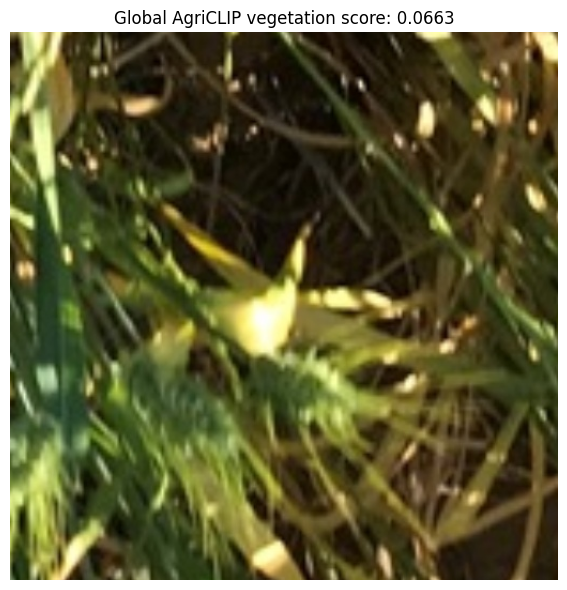

In [35]:
#visualize the tested image 
plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    sample_image
)

plt.title(
    "Global AgriCLIP vegetation score: "
    f"{sample_scores['vegetation_score'].item():.4f}"
)

plt.axis("off")
plt.tight_layout()
plt.show()

# AGRICLIP LOCALIZATION 
Image
   ↓
Split into overlapping patches
   ↓
DINO
   ↓
VegAnn aligner
   ↓
Similarity with vegetation prompts
   ↓
Heatmap
   ↓
Automatic box
   ↓
Automatic positive points

In [36]:
#Generate overlapping patches 

def create_overlapping_patches(
    image,
    patch_size=128,
    stride=64
):
    """
    Create overlapping image patches.

    Returns
    -------
    patches
        list of PIL images

    patch_locations
        list of (x,y)
    """

    image = ensure_rgb_pil(image)

    w, h = image.size

    patches = []
    patch_locations = []

    for y in range(0, h - patch_size + 1, stride):

        for x in range(0, w - patch_size + 1, stride):

            patch = image.crop(
                (
                    x,
                    y,
                    x + patch_size,
                    y + patch_size
                )
            )

            patches.append(patch)

            patch_locations.append((x, y))

    return patches, patch_locations


In [ ]:
#Test patch generation 
image = get_image(0)

patches, patch_locations = create_overlapping_patches(
    image
)

print("Image size:", image.size)
print("Number of patches:", len(patches))
print("First location:", patch_locations[0])
print("Last location:", patch_locations[-1])

""" 49 patches as (512-128)/64 +1 = 7

7 × 7 = 49"""

Image size: (512, 512)
Number of patches: 49
First location: (0, 0)
Last location: (384, 384)


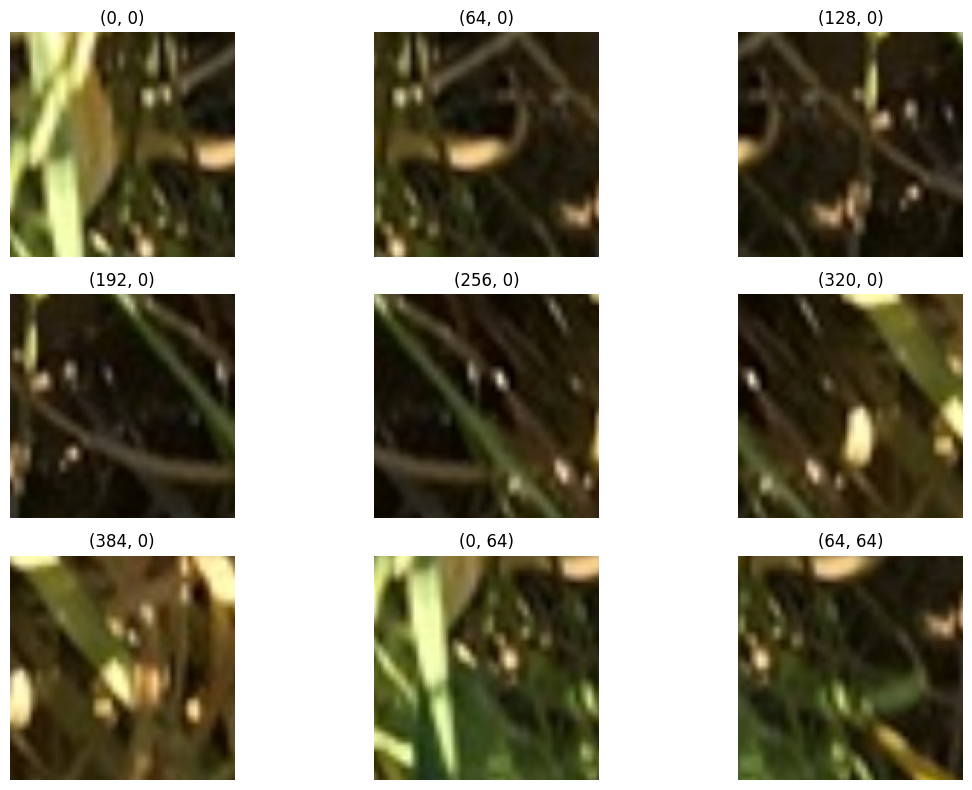

In [38]:
#Visualize several patches 
plt.figure(figsize=(12,8))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.imshow(patches[i])

    plt.title(
        str(patch_locations[i])
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
#Extract DINO features for many patches 
@torch.inference_mode()
def encode_patch_batch(
    patches,
    batch_size=16
):

    features = []

    for start in range(
        0,
        len(patches),
        batch_size
    ):

        batch = patches[
            start:
            start+batch_size
        ]

        batch_feature = extract_dino_features(
            batch
        )

        features.append(batch_feature)

    features = torch.cat(
        features,
        dim=0
    )

    return features

In [40]:
#Align every patch 
@torch.inference_mode()
def align_patch_features(
    dino_features
):

    aligned = align_dino_features(
        dino_features
    )

    return aligned

In [41]:
#give score to every patch 
@torch.inference_mode()
def score_patch_features(
    aligned_features
):

    scores = calculate_vegetation_scores(
        aligned_features
    )

    return scores["vegetation_score"]

In [42]:
#test the scoring 
patch_features = encode_patch_batch(
    patches
)

aligned_features = align_patch_features(
    patch_features
)

patch_scores = score_patch_features(
    aligned_features
)

print("Patch scores shape:")
print(patch_scores.shape)

print()

print("Minimum:",patch_scores.min().item())
print("Maximum:",patch_scores.max().item())
print("Mean:",patch_scores.mean().item())

Patch scores shape:
torch.Size([49])

Minimum: 0.043420255184173584
Maximum: 0.0758923888206482
Mean: 0.06372477114200592


In [43]:
#Convert patch score into a heatmap 
def patch_scores_to_heatmap(
    patch_scores,
    patch_locations,
    image_size=(512,512),
    patch_size=128
):

    heatmap = np.zeros(
        image_size,
        dtype=np.float32
    )

    counts = np.zeros(
        image_size,
        dtype=np.float32
    )

    for score,(x,y) in zip(
        patch_scores.cpu().numpy(),
        patch_locations
    ):

        heatmap[
            y:y+patch_size,
            x:x+patch_size
        ] += score

        counts[
            y:y+patch_size,
            x:x+patch_size
        ] += 1

    heatmap /= np.maximum(
        counts,
        1
    )

    return heatmap

In [44]:
#Normalize 
def normalize_heatmap(
    heatmap
):

    heatmap = heatmap - heatmap.min()

    if heatmap.max()>0:

        heatmap = heatmap/heatmap.max()

    return heatmap

In [45]:
#generate one heatmap 
heatmap = patch_scores_to_heatmap(

    patch_scores,

    patch_locations,

    image.size[::-1]
)

heatmap = normalize_heatmap(
    heatmap
)

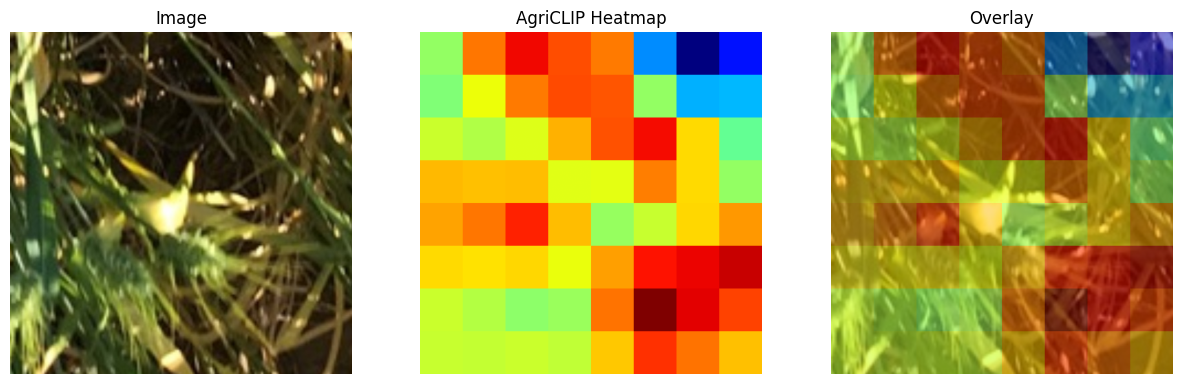

In [46]:
#visualize heatmap 
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image)
plt.axis("off")
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(
    heatmap,
    cmap="jet"
)
plt.axis("off")
plt.title("AgriCLIP Heatmap")

plt.subplot(1,3,3)
plt.imshow(image)
plt.imshow(
    heatmap,
    cmap="jet",
    alpha=0.5
)
plt.axis("off")
plt.title("Overlay")

plt.show()

In [47]:
# Move scores to NumPy for inspection

patch_scores_np = (
    patch_scores
    .detach()
    .cpu()
    .numpy()
)

num_to_show = 8

highest_indices = np.argsort(
    patch_scores_np
)[-num_to_show:][::-1]

lowest_indices = np.argsort(
    patch_scores_np
)[:num_to_show]


print("Highest-scoring patch indices:")
print(highest_indices)

print("\nHighest scores:")
print(patch_scores_np[highest_indices])

print("\nLowest-scoring patch indices:")
print(lowest_indices)

print("\nLowest scores:")
print(patch_scores_np[lowest_indices])

Highest-scoring patch indices:
[39 40 19  1 30 41 18 34]

Highest scores:
[0.07589239 0.07417792 0.07261288 0.07250237 0.07172072 0.0707441
 0.07040465 0.06920803]

Lowest-scoring patch indices:
[ 5  6 37 24 20 13  7 36]

Lowest scores:
[0.04342026 0.05035979 0.0567044  0.05782551 0.0584296  0.05855572
 0.05873752 0.05901766]


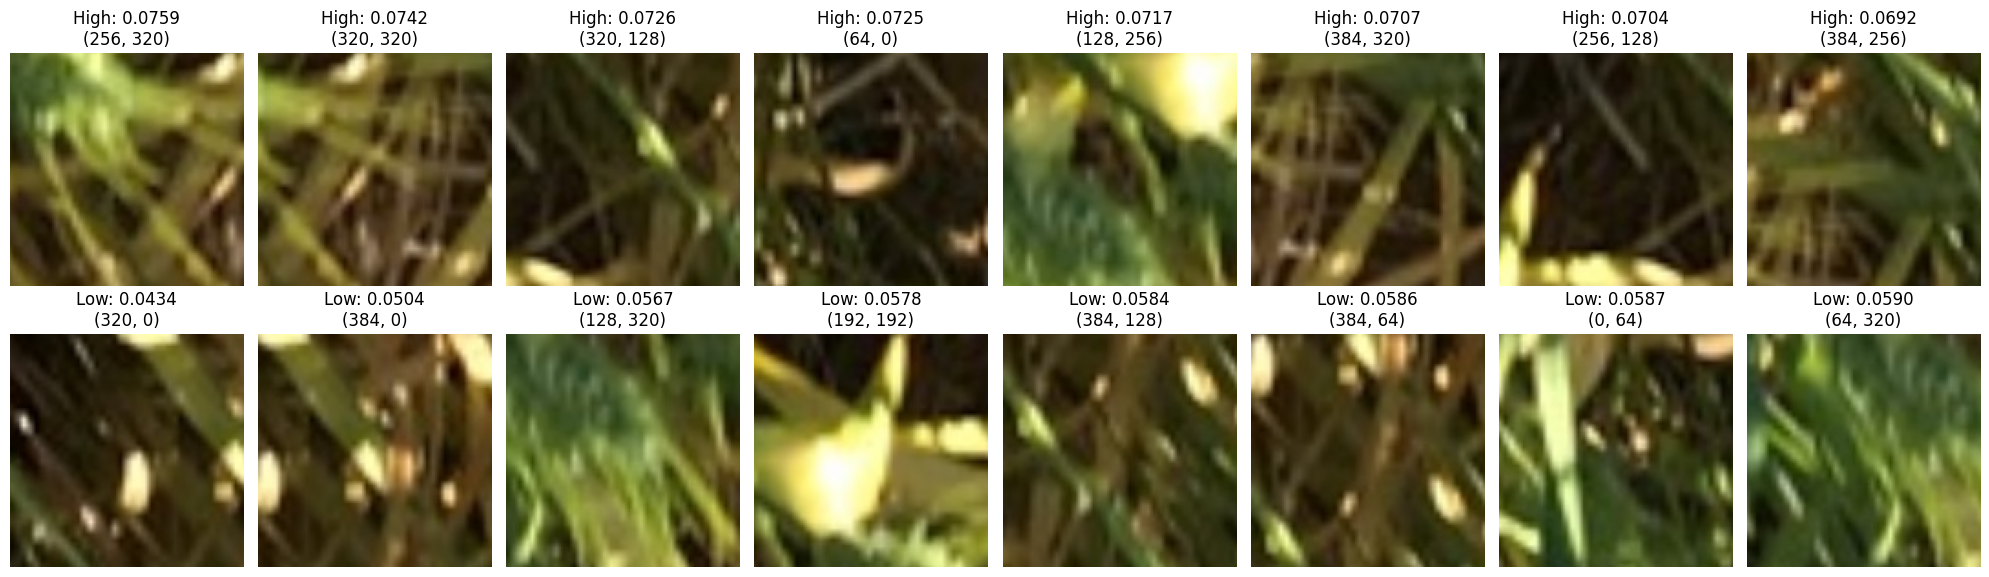

In [48]:
fig, axes = plt.subplots(
    2,
    num_to_show,
    figsize=(20, 6)
)

for column, patch_index in enumerate(highest_indices):

    axes[0, column].imshow(
        patches[patch_index]
    )

    axes[0, column].set_title(
        f"High: {patch_scores_np[patch_index]:.4f}\n"
        f"{patch_locations[patch_index]}"
    )

    axes[0, column].axis("off")


for column, patch_index in enumerate(lowest_indices):

    axes[1, column].imshow(
        patches[patch_index]
    )

    axes[1, column].set_title(
        f"Low: {patch_scores_np[patch_index]:.4f}\n"
        f"{patch_locations[patch_index]}"
    )

    axes[1, column].axis("off")


axes[0, 0].set_ylabel(
    "Highest scores",
    fontsize=12
)

axes[1, 0].set_ylabel(
    "Lowest scores",
    fontsize=12
)

plt.tight_layout()
plt.show()

In [49]:
patch_score_details = calculate_vegetation_scores(
    aligned_features
)

positive_patch_scores = (
    patch_score_details[
        "positive_similarity"
    ]
    .detach()
    .cpu()
)

negative_patch_scores = (
    patch_score_details[
        "negative_similarity"
    ]
    .detach()
    .cpu()
)

difference_patch_scores = (
    patch_score_details[
        "vegetation_score"
    ]
    .detach()
    .cpu()
)


print("Positive similarity")
print(
    "Min:",
    positive_patch_scores.min().item()
)
print(
    "Max:",
    positive_patch_scores.max().item()
)
print(
    "Mean:",
    positive_patch_scores.mean().item()
)


print("\nNegative similarity")
print(
    "Min:",
    negative_patch_scores.min().item()
)
print(
    "Max:",
    negative_patch_scores.max().item()
)
print(
    "Mean:",
    negative_patch_scores.mean().item()
)


print("\nPositive minus negative")
print(
    "Min:",
    difference_patch_scores.min().item()
)
print(
    "Max:",
    difference_patch_scores.max().item()
)
print(
    "Mean:",
    difference_patch_scores.mean().item()
)

Positive similarity
Min: 0.5542523860931396
Max: 0.6415939927101135
Mean: 0.5999506711959839

Negative similarity
Min: 0.5063541531562805
Max: 0.5768383145332336
Mean: 0.5362258553504944

Positive minus negative
Min: 0.043420255184173584
Max: 0.0758923888206482
Mean: 0.06372477859258652


In [50]:
def contrastive_probability(
    positive_scores,
    negative_scores,
    temperature=0.07
):
    """
    Convert positive and negative similarities into
    a two-class vegetation probability.
    """

    logits = torch.stack(
        [
            negative_scores,
            positive_scores
        ],
        dim=1
    )

    probabilities = torch.softmax(
        logits / temperature,
        dim=1
    )

    vegetation_probability = probabilities[:, 1]

    return vegetation_probability

In [51]:
positive_only_scores = positive_patch_scores

difference_scores = (
    positive_patch_scores
    - negative_patch_scores
)

probability_scores = contrastive_probability(
    positive_patch_scores,
    negative_patch_scores,
    temperature=0.07
)


print(
    "Positive-only range:",
    positive_only_scores.min().item(),
    "to",
    positive_only_scores.max().item()
)

print(
    "Difference range:",
    difference_scores.min().item(),
    "to",
    difference_scores.max().item()
)

print(
    "Probability range:",
    probability_scores.min().item(),
    "to",
    probability_scores.max().item()
)

Positive-only range: 0.5542523860931396 to 0.6415939927101135
Difference range: 0.043420255184173584 to 0.0758923888206482
Probability range: 0.6502843499183655 to 0.7472836971282959


In [52]:
positive_heatmap = patch_scores_to_heatmap(
    positive_only_scores,
    patch_locations,
    image_size=(
        image.height,
        image.width
    ),
    patch_size=128
)

difference_heatmap = patch_scores_to_heatmap(
    difference_scores,
    patch_locations,
    image_size=(
        image.height,
        image.width
    ),
    patch_size=128
)

probability_heatmap = patch_scores_to_heatmap(
    probability_scores,
    patch_locations,
    image_size=(
        image.height,
        image.width
    ),
    patch_size=128
)


positive_heatmap = normalize_heatmap(
    positive_heatmap
)

difference_heatmap = normalize_heatmap(
    difference_heatmap
)

probability_heatmap = normalize_heatmap(
    probability_heatmap
)

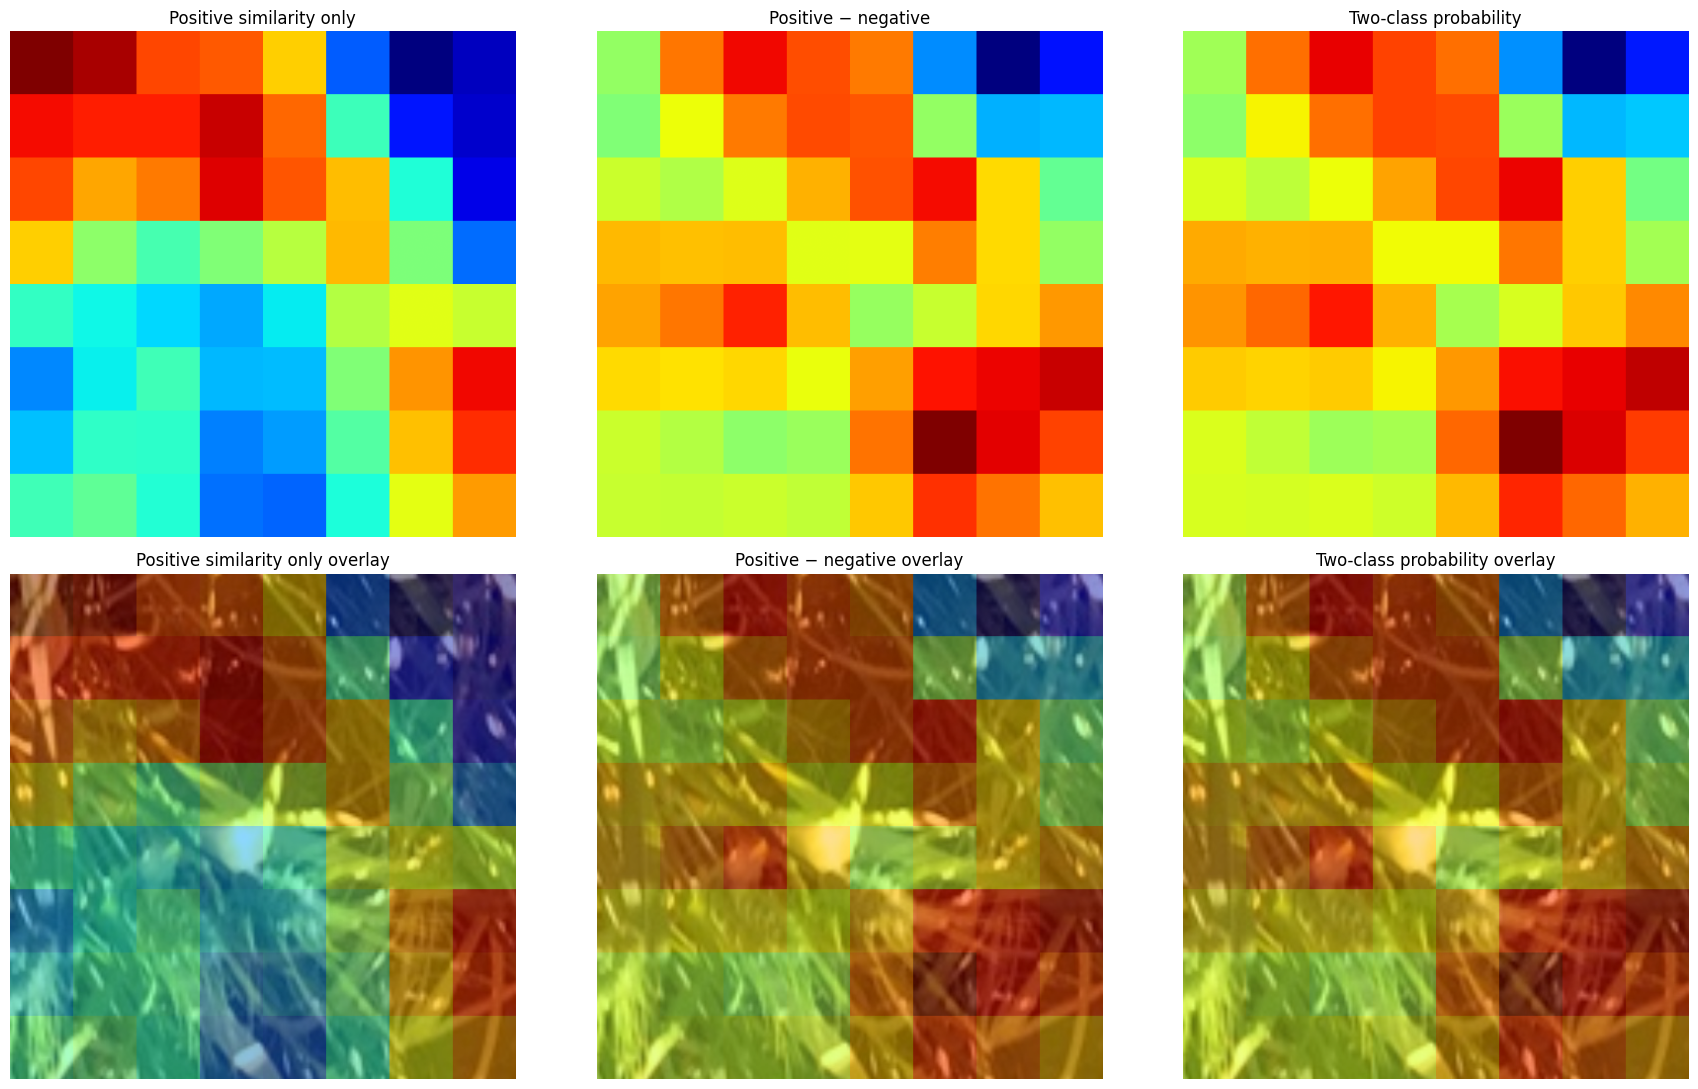

In [53]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 11)
)

heatmaps = [
    positive_heatmap,
    difference_heatmap,
    probability_heatmap
]

titles = [
    "Positive similarity only",
    "Positive − negative",
    "Two-class probability"
]


for index, (
    current_heatmap,
    title
) in enumerate(zip(heatmaps, titles)):

    axes[0, index].imshow(
        current_heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )

    axes[0, index].set_title(
        title
    )

    axes[0, index].axis("off")


    axes[1, index].imshow(
        image
    )

    axes[1, index].imshow(
        current_heatmap,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    axes[1, index].set_title(
        title + " overlay"
    )

    axes[1, index].axis("off")


plt.tight_layout()
plt.show()